# What drives salaries in data jobs?

I used the Kaggle dataset **Jobs and Salaries in Data Science** (9,355 salary records, 2020-2023) to answer five questions:

1. How much does experience change salary?
2. Which job categories pay the most?
3. Does remote work pay less?
4. How big is the gap between countries?
5. Did salaries actually go up from 2022 to 2023?

After that I trained a few models to see how well salary can be predicted from these columns.

One rule I followed throughout: **compare like with like**. Most comparisons are done within the same experience level (and within the US when the country could distort the result).

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

DATA_PATH = "jobs_in_data.csv"   # change this to where you saved the Kaggle file
os.makedirs("images", exist_ok=True)

LEVELS = ["Entry-level", "Mid-level", "Senior", "Executive"]

# show axis numbers as $50k, $100k, ...
def money(value, position):
    return f"${value/1000:.0f}k"

## 1. First look at the data

In [6]:
raw = pd.read_csv(DATA_PATH)

print("Shape:", raw.shape)
print("Exact duplicate rows:", raw.duplicated().sum())
print("Missing values:", raw.isna().sum().sum())
raw.head()

Shape: (9355, 12)
Exact duplicate rows: 4014
Missing values: 0


,work_year,job_title,job_category,salary_currency,salary,salary_in_usd,employee_residence,experience_level,employment_type,work_setting,company_location,company_size
0,2023,Data DevOps Engineer,Data Engineering,EUR,88000,95012,Germany,Mid-level,Full-time,Hybrid,Germany,L
1,2023,Data Architect,Data Architecture and Modeling,USD,186000,186000,United States,Senior,Full-time,In-person,United States,M
2,2023,Data Architect,Data Architecture and Modeling,USD,81800,81800,United States,Senior,Full-time,In-person,United States,M
3,2023,Data Scientist,Data Science and Research,USD,212000,212000,United States,Senior,Full-time,In-person,United States,M
4,2023,Data Scientist,Data Science and Research,USD,93300,93300,United States,Senior,Full-time,In-person,United States,M


In [7]:
for col in ["job_category", "experience_level", "employment_type", "work_setting", "company_size"]:
    print(raw[col].value_counts().to_string(), "\n")

print("Distinct job titles:", raw["job_title"].nunique())
print("Share of rows from US companies:", f"{(raw['company_location'] == 'United States').mean():.0%}")

job_category
Data Science and Research         3014
Data Engineering                  2260
Data Analysis                     1457
Machine Learning and AI           1428
Leadership and Management          503
BI and Visualization               313
Data Architecture and Modeling     259
Data Management and Strategy        61
Data Quality and Operations         55
Cloud and Database                   5 

experience_level
Senior         6709
Mid-level      1869
Entry-level     496
Executive       281 

employment_type
Full-time    9310
Contract       19
Part-time      15
Freelance      11 

work_setting
In-person    5730
Remote       3434
Hybrid        191 

company_size
M    8448
L     748
S     159 

Distinct job titles: 125
Share of rows from US companies: 87%


What I noticed:

- **43% of the rows are exact duplicates** (4,014 of 9,355). There is no ID column, so I can't tell repeated submissions from real people with identical values. For the model they have to go, otherwise the same row can end up in both the training and the test set.
- `salary_in_usd` is the target. `salary` is the same number in local currency, and `salary_currency` mostly gives away the country, so both get dropped.
- **99.5% of rows are full-time.** Part-time and contract pay isn't comparable, and there are too few of them anyway.
- **87% of rows are US companies**, so comparing 70 countries one by one isn't possible. I'll group them into regions.
- `job_category` already groups the 125 job titles into 10 categories, so I don't need to do that myself.

## 2. Cleaning

In [8]:
df = raw.drop_duplicates()
print("After removing duplicates:", df.shape)

df = df[df["employment_type"] == "Full-time"]
df = df.drop(columns=["salary", "salary_currency", "employment_type", "employee_residence"])

EUROPE = {"Germany", "France", "Spain", "Portugal", "Netherlands", "Ireland", "Italy", "Poland",
          "Switzerland", "Austria", "Belgium", "Sweden", "Denmark", "Finland", "Norway", "Greece",
          "Czech Republic", "Czechia", "Romania", "Lithuania", "Estonia", "Latvia", "Hungary",
          "Croatia", "Slovenia", "Luxembourg", "Malta", "Ukraine", "Bulgaria", "Slovakia"}

def to_region(country):
    if country in ("United States", "United Kingdom", "Canada"):
        return country
    return "Other Europe" if country in EUROPE else "Rest of World"

df = df.assign(region=df["company_location"].map(to_region))
print("After keeping full-time only:", df.shape)

print("\nRows per year:\n", df["work_year"].value_counts().sort_index().to_string())
print("\nRows per region:\n", df["region"].value_counts().to_string())

After removing duplicates: (5341, 12)
After keeping full-time only: (5296, 9)

Rows per year:
 work_year
2020      65
2021     185
2022    1082
2023    3964

Rows per region:
 region
United States     4278
United Kingdom     358
Other Europe       325
Canada             195
Rest of World      140


2020 and 2021 only have 65 and 185 rows, so for trends I'll only compare 2022 with 2023.

### Checking extreme salaries

Before removing anything I looked at the lowest and highest salaries in each experience level, together with the country and job title.

In [9]:
cols = ["experience_level", "job_title", "company_location", "work_year", "salary_in_usd"]
print("Lowest:")
print(df.sort_values("salary_in_usd").groupby("experience_level").head(3)[cols].to_string(index=False))
print("\nHighest:")
print(df.sort_values("salary_in_usd", ascending=False).groupby("experience_level").head(3)[cols].to_string(index=False))

Lowest:
experience_level                       job_title company_location  work_year  salary_in_usd
     Entry-level      Machine Learning Developer         Thailand       2021          15000
       Executive              Staff Data Analyst           Canada       2020          15000
       Mid-level Business Intelligence Developer            Ghana       2022          15000
     Entry-level                    Data Analyst        Indonesia       2022          15000
     Entry-level                  Data Scientist          Ecuador       2023          16000
       Mid-level           Business Data Analyst           Russia       2023          17000
       Mid-level               Big Data Engineer          Moldova       2021          18000
          Senior                      BI Analyst           Turkey       2023          18381
          Senior        Computer Vision Engineer           Brazil       2021          18907
          Senior                  Data Scientist           Turkey       

Most of these look real. \$15-20k salaries come from Thailand, Ghana, Indonesia, Turkey and similar countries, and \$400k+ salaries are senior research and data roles in the US.

Three rows don't make sense, so I removed them:

- an "Executive" Staff Data Analyst in Canada earning \$15,000
- two mid-level jobs in the UK (Data Analyst and Analytics Engineer) at about \$430,000

The usual IQR rule flagged 90 rows, but it compares salaries across all countries at once, so it mostly flags low pay in cheaper countries and high US big-tech pay. I kept those and use medians everywhere, which aren't pulled around by extreme values.

In [10]:
implausible = (
    ((df["experience_level"] == "Executive") & (df["company_location"] == "Canada") & (df["salary_in_usd"] == 15000))
    | ((df["experience_level"] == "Mid-level") & (df["company_location"] == "United Kingdom") & (df["salary_in_usd"] > 400000))
)
print("Removing", implausible.sum(), "rows")

df = df[~implausible].reset_index(drop=True)
df.to_csv("jobs_clean.csv", index=False)
print("Clean dataset:", df.shape)

Removing 3 rows
Clean dataset: (5293, 9)


Final dataset: **5,293 rows** (9,355 raw, minus 4,014 duplicates, 45 non-full-time rows and 3 implausible salaries).

## 3. Analysis

### Q1. How much does experience change salary?

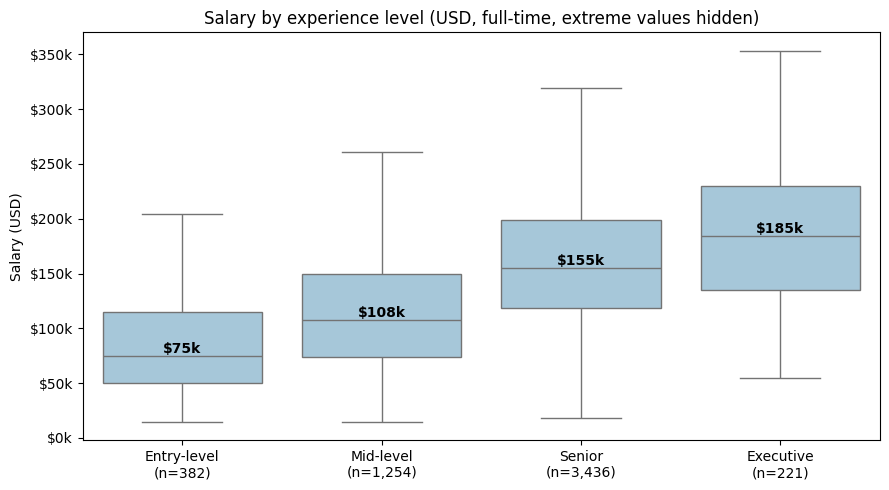

experience_level
Entry-level     75000.0
Mid-level      108000.0
Senior         155000.0
Executive      184560.0
Name: salary_in_usd, dtype: float64
Entry-level to Senior: +107%


In [11]:
counts = df["experience_level"].value_counts().reindex(LEVELS)
medians = df.groupby("experience_level")["salary_in_usd"].median().reindex(LEVELS)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="experience_level", y="salary_in_usd", order=LEVELS, color="#9ecae1", showfliers=False, ax=ax)
for i, m in enumerate(medians):
    ax.text(i, m, f"${m/1000:.0f}k", ha="center", va="bottom", fontweight="bold")
ax.set_xticks(range(len(LEVELS)), [f"{lvl}\n(n={n:,})" for lvl, n in zip(LEVELS, counts)])
ax.set_title("Salary by experience level (USD, full-time, extreme values hidden)")
ax.set_xlabel("")
ax.set_ylabel("Salary (USD)")
ax.yaxis.set_major_formatter(money)
plt.tight_layout()
plt.savefig("images/q1_salary_by_level.png", dpi=150)
plt.show()

print(medians)
print(f"Entry-level to Senior: {medians['Senior'] / medians['Entry-level'] - 1:+.0%}")

Median salary goes from **\$75k at entry level to \$155k at senior level**, so it roughly doubles. The boxes overlap a lot though: the top quarter of mid-level salaries reaches about \$150k, close to a typical senior salary. Experience matters, but something else explains a big part of the spread, which is what the next questions look at.

### Q2. Which job categories pay the most?

I only used Senior rows here, so the comparison isn't mixed up with experience. Categories with fewer than 30 people are left out.

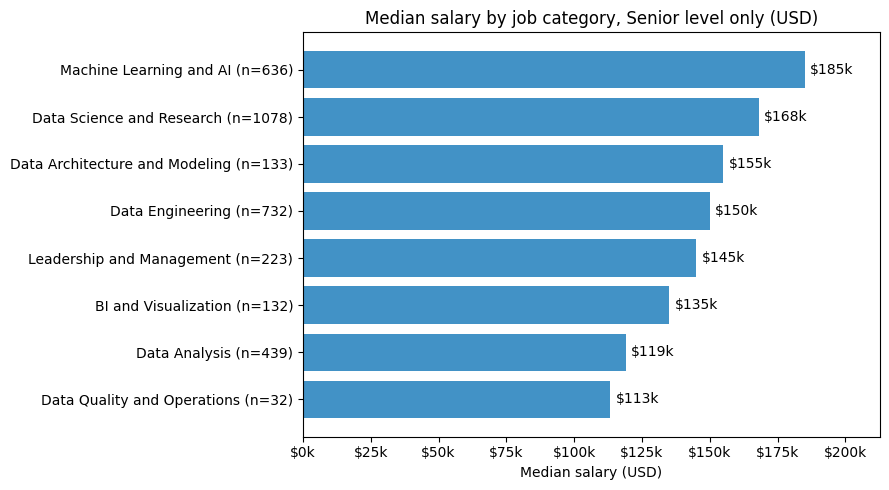

                                  median     n
job_category                                  
Machine Learning and AI         185000.0   636
Data Science and Research       168000.0  1078
Data Architecture and Modeling  155000.0   133
Data Engineering                150000.0   732
Leadership and Management       145000.0   223
BI and Visualization            135000.0   132
Data Analysis                   119000.0   439
Data Quality and Operations     113200.0    32


In [12]:
senior = df[df["experience_level"] == "Senior"]
by_cat = (senior.groupby("job_category")["salary_in_usd"]
          .agg(median="median", n="count")
          .query("n >= 30")
          .sort_values("median"))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh([f"{cat} (n={n})" for cat, n in zip(by_cat.index, by_cat["n"])], by_cat["median"], color="#4292c6")
ax.bar_label(bars, labels=[f"${m/1000:.0f}k" for m in by_cat["median"]], padding=4)
ax.set_title("Median salary by job category, Senior level only (USD)")
ax.set_xlabel("Median salary (USD)")
ax.xaxis.set_major_formatter(money)
ax.set_xlim(0, by_cat["median"].max() * 1.15)
plt.tight_layout()
plt.savefig("images/q2_salary_by_category_senior.png", dpi=150)
plt.show()

print(by_cat.sort_values("median", ascending=False))

ML jobs might just be more common in the US, where pay is higher. To check that, I repeated it with US jobs only:

In [13]:
us_senior = senior[senior["region"] == "United States"]
print(us_senior.groupby("job_category")["salary_in_usd"]
      .agg(median="median", n="count").query("n >= 30").sort_values("median", ascending=False))

                                  median    n
job_category                                 
Machine Learning and AI         190713.5  518
Data Science and Research       172000.0  964
Data Architecture and Modeling  160000.0  121
Data Engineering                156925.0  634
Leadership and Management       147500.0  195
BI and Visualization            135000.0  119
Data Analysis                   120600.0  373
Data Quality and Operations     113200.0   30


**Machine Learning & AI pays the most (\$185k), about 55% more than Data Analysis (\$119k).** The order is the same with US jobs only (ML & AI is still first at \$191k), so it isn't just a country effect.

Leadership & Management ranks lower than I expected. That group mixes many different titles, and executives are a separate experience level, so they aren't in this chart. Data Quality & Operations only has 32 people, so its median is rough.

### Q3. Does remote work pay less?

US only, so country doesn't get in the way, and split by experience level. I left out Hybrid because it has very few rows. To check if the gaps are real I used the Mann-Whitney U test, which works for skewed data like salaries.

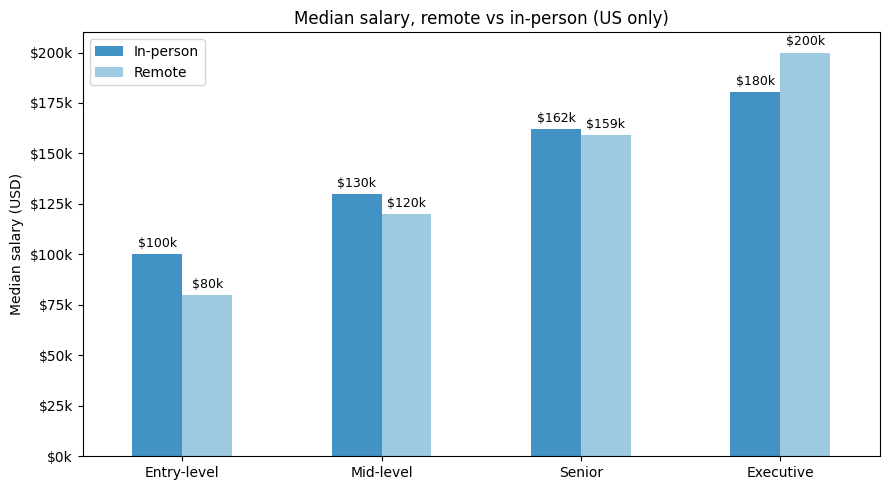

Entry-level  remote n= 104  in-person n= 127  gap=-20%  p=0.001
Mid-level    remote n= 313  in-person n= 531  gap=-8%  p=0.007
Senior       remote n=1243  in-person n=1730  gap=-2%  p=0.038
Executive    remote n=  90  in-person n=  99  gap=+11%  p=0.063


In [14]:
us = df[(df["region"] == "United States") & (df["work_setting"].isin(["Remote", "In-person"]))]

remote = (us.groupby(["experience_level", "work_setting"])["salary_in_usd"]
          .median().unstack().reindex(LEVELS))

ax = remote.plot(kind="bar", figsize=(9, 5), color={"In-person": "#4292c6", "Remote": "#9ecae1"}, rot=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f"${v/1000:.0f}k" for v in container.datavalues], padding=3, fontsize=9)
ax.set_title("Median salary, remote vs in-person (US only)")
ax.set_xlabel("")
ax.set_ylabel("Median salary (USD)")
ax.yaxis.set_major_formatter(money)
ax.legend(title="")
plt.tight_layout()
plt.savefig("images/q3_remote_vs_inperson_us.png", dpi=150)
plt.show()

for lvl in LEVELS:
    rem = us.loc[(us["experience_level"] == lvl) & (us["work_setting"] == "Remote"), "salary_in_usd"]
    inp = us.loc[(us["experience_level"] == lvl) & (us["work_setting"] == "In-person"), "salary_in_usd"]
    p = mannwhitneyu(rem, inp).pvalue
    gap = rem.median() / inp.median() - 1
    print(f"{lvl:12s} remote n={len(rem):4d}  in-person n={len(inp):4d}  gap={gap:+.0%}  p={p:.3f}")

Remote pays less early in a career: **-20% at entry level (p=0.001) and -8% at mid-level (p=0.007)**. At senior level the gap is only -2%. It's statistically significant because the group is big, but \$3k on a \$160k salary hardly matters. Remote executives look better paid (+11%), but p=0.063, so that could be chance.

Since I ran four tests, a stricter cutoff (0.05 / 4 = 0.0125) is safer. Entry and mid-level still pass it, so the main conclusion stays the same.

### Q4. How big is the gap between countries?

Senior level only.

                  median     n vs_US
region                              
United States   160000.0  2984   +0%
Canada          144200.0   142  -10%
United Kingdom  117700.0   133  -26%
Other Europe     75577.0   127  -53%
Rest of World    78013.0    50  -51%


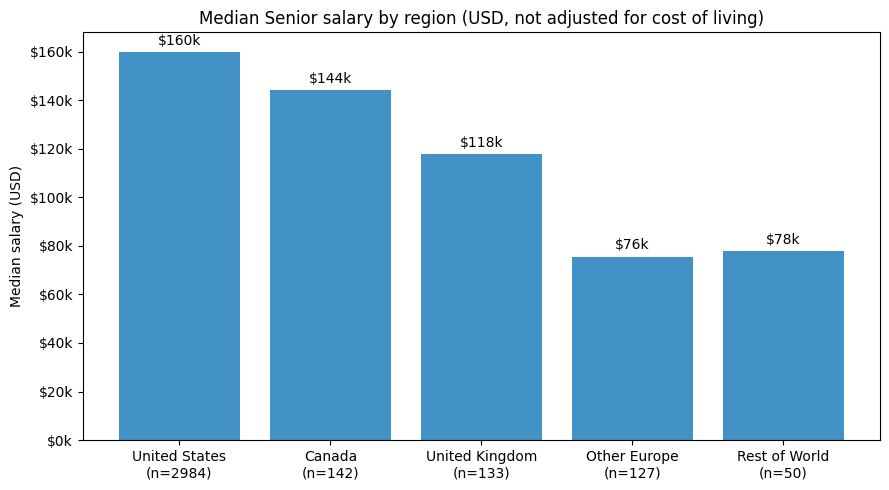

In [15]:
REGIONS = ["United States", "Canada", "United Kingdom", "Other Europe", "Rest of World"]
by_region = senior.groupby("region")["salary_in_usd"].agg(median="median", n="count").reindex(REGIONS)
by_region["vs_US"] = (by_region["median"] / by_region.loc["United States", "median"] - 1).map("{:+.0%}".format)
print(by_region)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([f"{r}\n(n={n})" for r, n in zip(by_region.index, by_region["n"])], by_region["median"], color="#4292c6")
ax.bar_label(bars, labels=[f"${m/1000:.0f}k" for m in by_region["median"]], padding=3)
ax.set_title("Median Senior salary by region (USD, not adjusted for cost of living)")
ax.set_ylabel("Median salary (USD)")
ax.yaxis.set_major_formatter(money)
plt.tight_layout()
plt.savefig("images/q4_senior_salary_by_region.png", dpi=150)
plt.show()

A senior in the US earns a median of **\$160k**: 10% more than in Canada, 26% more than in the UK and roughly **double** the rest of Europe (\$76k). These are USD amounts, not adjusted for cost of living, taxes or benefits, so it doesn't mean people in the US are twice as well off. "Rest of World" only has 50 people from very different countries, so I wouldn't read much into it.

### Q5. Did salaries go up from 2022 to 2023?

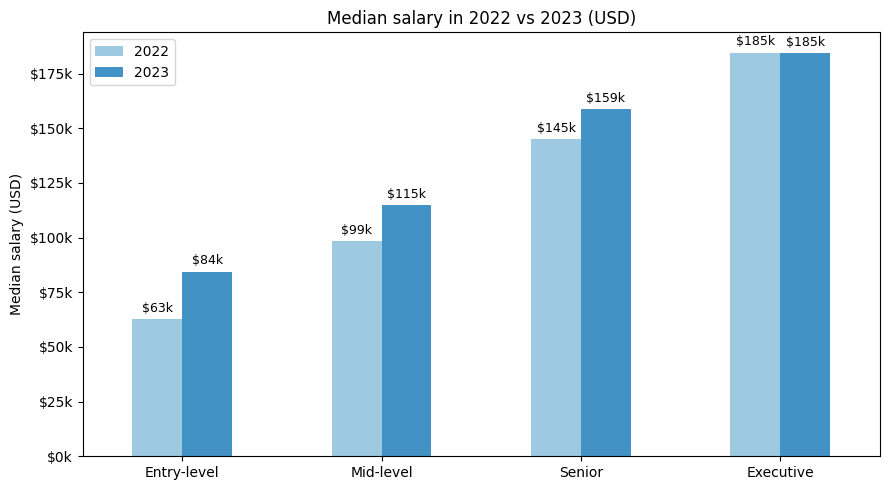

Entry-level  2022 n=  90  2023 n= 238  change=+35%  p=0.002
Mid-level    2022 n= 271  2023 n= 884  change=+17%  p=0.000
Senior       2022 n= 682  2023 n=2670  change=+9%  p=0.000
Executive    2022 n=  38  2023 n= 171  change=-0%  p=0.908


In [16]:
two_years = df[df["work_year"].isin([2022, 2023])]
yearly = (two_years.groupby(["experience_level", "work_year"])["salary_in_usd"]
          .median().unstack().reindex(LEVELS))

ax = yearly.plot(kind="bar", figsize=(9, 5), color={2022: "#9ecae1", 2023: "#4292c6"}, rot=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f"${v/1000:.0f}k" for v in container.datavalues], padding=3, fontsize=9)
ax.set_title("Median salary in 2022 vs 2023 (USD)")
ax.set_xlabel("")
ax.set_ylabel("Median salary (USD)")
ax.yaxis.set_major_formatter(money)
ax.legend(title="")
plt.tight_layout()
plt.savefig("images/q5_salary_2022_vs_2023.png", dpi=150)
plt.show()

for lvl in LEVELS:
    a = two_years.loc[(two_years["experience_level"] == lvl) & (two_years["work_year"] == 2022), "salary_in_usd"]
    b = two_years.loc[(two_years["experience_level"] == lvl) & (two_years["work_year"] == 2023), "salary_in_usd"]
    change = b.median() / a.median() - 1
    print(f"{lvl:12s} 2022 n={len(a):4d}  2023 n={len(b):4d}  change={change:+.0%}  p={mannwhitneyu(a, b).pvalue:.3f}")

At first this looks like big raises, especially for juniors (+35% at entry level). But 2023 has almost four times more rows than 2022, so I checked whether the mix of countries changed:

In [17]:
print(pd.crosstab(two_years["work_year"], two_years["region"], normalize="index").round(3))

us_yearly = (two_years[two_years["region"] == "United States"]
             .groupby(["experience_level", "work_year"])["salary_in_usd"]
             .median().unstack().reindex(LEVELS))
print("\nUS only, change 2022 -> 2023:")
print((us_yearly[2023] / us_yearly[2022] - 1).map("{:+.0%}".format))

region     Canada  Other Europe  Rest of World  United Kingdom  United States
work_year                                                                    
2022        0.033         0.084          0.040           0.069          0.773
2023        0.037         0.042          0.018           0.066          0.838

US only, change 2022 -> 2023:
experience_level
Entry-level    +8%
Mid-level      +2%
Senior         +9%
Executive      -6%
dtype: object


It did. US jobs went from **77% of the data in 2022 to 84% in 2023**, while the lower-paying regions shrank. Within the US, the increases are much smaller: **+8% entry, +2% mid, +9% senior** (the -6% for executives is based on a small 2022 group).

So most of the jump in the overall numbers comes from **which countries are in the data**, not from people getting paid more. This is a composition effect, and it's the main reason I compare within groups in this notebook.

## 4. Salary prediction model

Can these columns predict salary? Setup:

- Features: experience level, job category, region, work setting, company size and year, turned into 0/1 columns with `get_dummies`. For each feature I leave out one reference category (Entry-level, Data Analysis, United States, In-person, medium company, 2023)
- 80/20 train/test split, stratified by experience level
- I predict log(salary) instead of salary, because salaries are right-skewed (a few very high ones)
- Baseline to beat: just guess the median salary of the same job category and experience level

In [18]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

FEATURES = ["experience_level", "job_category", "region", "work_setting", "company_size", "work_year"]
X = pd.get_dummies(df[FEATURES].astype(str), dtype=int)

# one category per feature is left out as the reference; the model's effects are measured against these
REFERENCE = ["experience_level_Entry-level", "job_category_Data Analysis", "region_United States",
             "work_setting_In-person", "company_size_M", "work_year_2023"]
X = X.drop(columns=REFERENCE)
y = df["salary_in_usd"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df["experience_level"])
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4234, 23)  Test: (1059, 23)


**Baseline.** For each test row, look up the median training salary for its job category and experience level. A model is only useful if it beats this.

In [19]:
train_rows = df.loc[X_train.index]
test_rows = df.loc[X_test.index]

lookup = train_rows.groupby(["job_category", "experience_level"])["salary_in_usd"].median()
baseline_pred = []
for _, row in test_rows.iterrows():
    key = (row["job_category"], row["experience_level"])
    baseline_pred.append(lookup.get(key, y_train.median()))

print(f"Baseline MAE: ${mean_absolute_error(y_test, baseline_pred):,.0f}")

Baseline MAE: $43,846


**Models.** Each model is trained on log(salary), and I convert the predictions back with `np.exp`. To check the results aren't luck from one split, I also run 5-fold cross-validation on the training set: train on 4/5, test on the remaining 1/5, five times.

In [20]:
models = {
    "Linear regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

def cv_mae(model):
    errors = []
    for fit_idx, val_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(X_train):
        model.fit(X_train.iloc[fit_idx], np.log(y_train.iloc[fit_idx]))
        pred = np.exp(model.predict(X_train.iloc[val_idx]))
        errors.append(mean_absolute_error(y_train.iloc[val_idx], pred))
    return np.mean(errors)

results = [{"model": "Baseline", "cv_MAE": None,
            "test_MAE": mean_absolute_error(y_test, baseline_pred), "test_R2": r2_score(y_test, baseline_pred)}]
for name, model in models.items():
    cv = cv_mae(model)
    model.fit(X_train, np.log(y_train))
    pred = np.exp(model.predict(X_test))
    results.append({"model": name, "cv_MAE": cv,
                    "test_MAE": mean_absolute_error(y_test, pred), "test_R2": r2_score(y_test, pred)})

results = pd.DataFrame(results).set_index("model")
baseline_mae = results.loc["Baseline", "test_MAE"]
results["vs_baseline"] = (results["test_MAE"] / baseline_mae - 1).map("{:+.1%}".format)
results.round(3)

,cv_MAE,test_MAE,test_R2,vs_baseline
model,,,,
Baseline,NaN,43845.781,0.258,+0.0%
Linear regression,40549.809,40038.236,0.354,-8.7%
Random Forest,41191.414,40324.059,0.346,-8.0%
Gradient Boosting,40836.624,40202.786,0.343,-8.3%


All three models beat the baseline by about 9% (MAE around **\$40k**, R² around **0.36**), and the cross-validation MAE is close to the test MAE, so the result is stable.

The three models are basically tied. I chose the model by **cross-validation score, not test score**, so the test set isn't used for the decision. Linear regression is the simplest and easiest to explain, and the tree models don't add anything, probably because with only a few broad categories salary behaves almost additively.

A nice thing about linear regression on log(salary) is that each coefficient can be read as a percentage. For example, a coefficient of 0.10 for a category means about +10% salary compared with the reference category (for example, UK compared with the US).

In [21]:
final_model = models["Linear regression"]
final_model.fit(X_train, np.log(y_train))

effects = pd.Series(np.exp(final_model.coef_) - 1, index=X_train.columns).sort_values()
print("Compared with: Entry-level, Data Analysis, United States, In-person, medium company, 2023")
print("\nBiggest effects on salary:")
print(pd.concat([effects.head(5), effects.tail(5)]).map("{:+.0%}".format))

Compared with: Entry-level, Data Analysis, United States, In-person, medium company, 2023

Biggest effects on salary:
region_Other Europe                         -51%
region_Rest of World                        -50%
region_United Kingdom                       -29%
job_category_Data Quality and Operations    -16%
region_Canada                               -10%
experience_level_Mid-level                  +30%
job_category_Data Science and Research      +38%
job_category_Machine Learning and AI        +54%
experience_level_Senior                     +66%
experience_level_Executive                  +97%
dtype: object


The biggest effects come from **region**, **experience level** and **job category**, the same three things that explained the big differences in Q1, Q2 and Q4. Year, work setting and company size have small effects.

**Limitations:** R² of 0.36 means most of the variation in salary isn't explained by these columns. The dataset has nothing on the company itself, skills, education or negotiation, which all matter a lot. An error of about \$40k (roughly 28% of a typical salary) is fine for a ballpark estimate, not for predicting a specific offer.

## Summary

- Experience roughly doubles pay from entry level to senior (\$75k to \$155k).
- At the same level, ML & AI jobs pay the most, about 55% more than data analysis.
- In the US, remote work pays less for juniors (-20%) but hardly at all for seniors.
- A senior in the US earns about twice the rest of Europe (not adjusted for cost of living).
- The big 2022 to 2023 increase is mostly a change in which countries are in the data. Within the US, salaries rose 2-9%.
- A simple linear model predicts salary about 9% better than the baseline, but these columns only explain about a third of the variation.

The data is self-reported and mostly from US companies and senior people, so these results describe this sample and won't necessarily hold elsewhere, for example in Indonesia.